c:\Users\lenovo\Desktop\yoho-ml-training\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\lenovo\AppData\Local\Temp\ipykernel_3160\4289226681.py:26: Pandas4Warning: The inplace keyword in DataFrame.drop_duplicates is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop_duplicates(inplace=True)
C:\Users\lenovo\AppData\Local\Temp\ipykernel_3160\4289226681.py:28: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(columns=['customerID'], inplace=True)


Shape: (7043, 20)
Data Types:
 gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                 int64
dtype: object
Missing Values:
 TotalCharges    11
dtype: int64
Class Balance:
 Churn
0    0.7346
1    0.2654
Name: proportion, dtype: float64


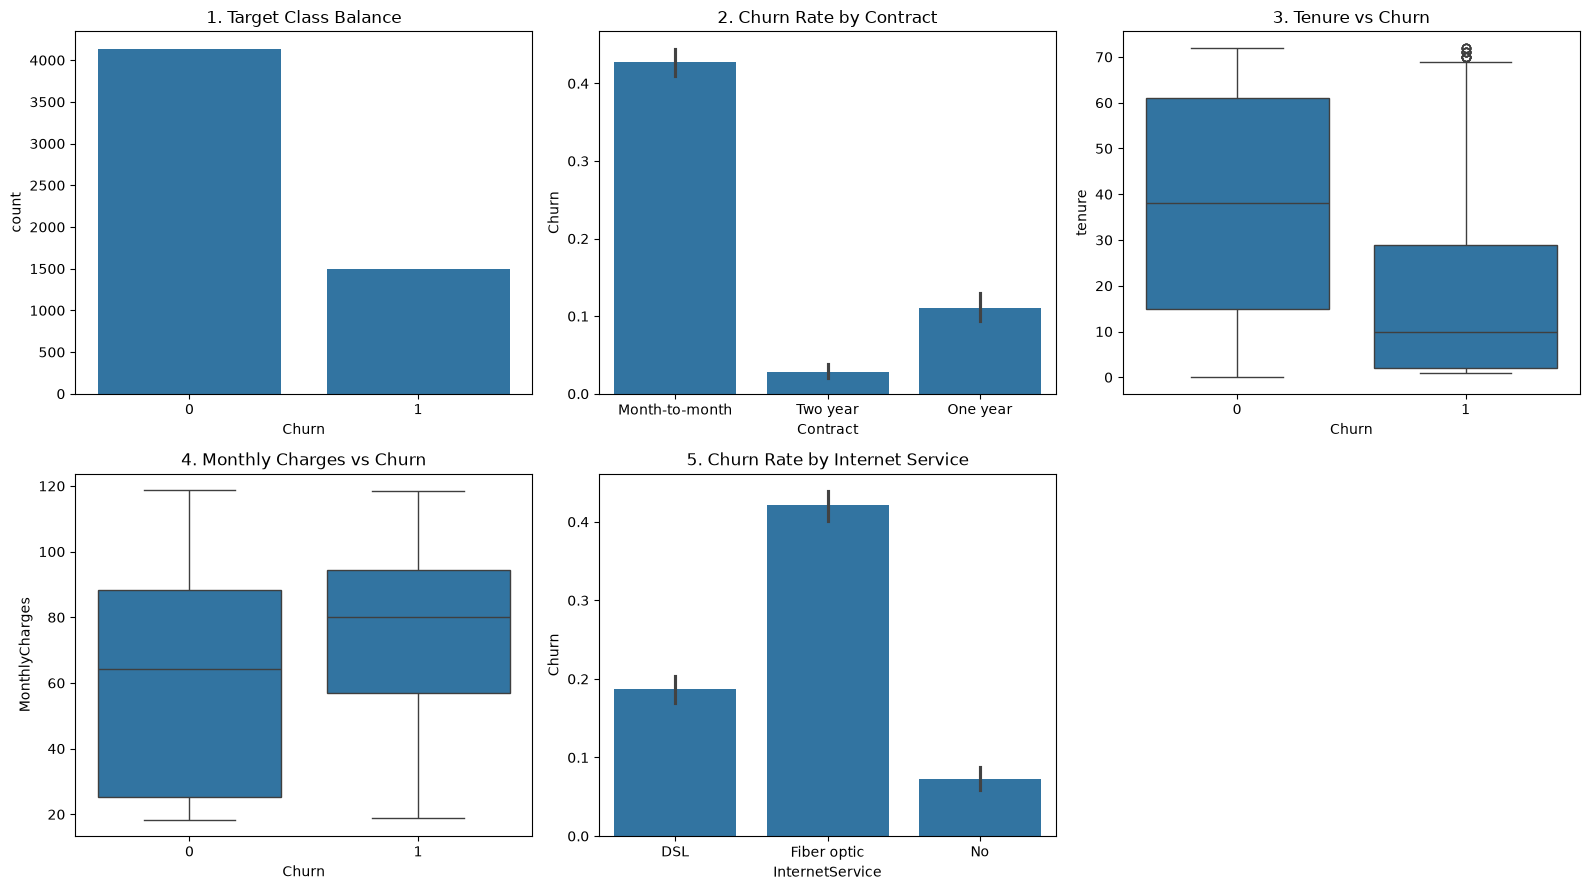


Part 1 Baseline Results:
 | Model               |   CV ROC-AUC |   CV F1 |
|:--------------------|-------------:|--------:|
| Dummy Classifier    |       0.5065 |  0.2762 |
| Logistic Regression |       0.8457 |  0.6287 |
| Random Forest       |       0.8283 |  0.61   |


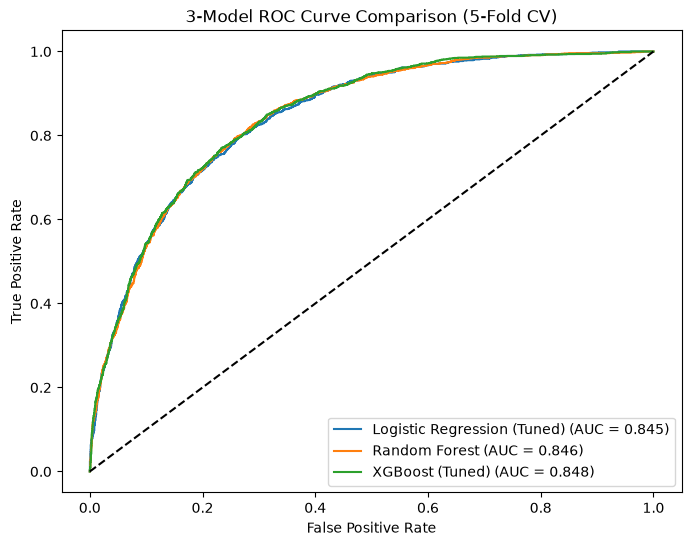


Part 2 Model Comparison:
 | Model                       |   CV ROC-AUC |   CV F1 |
|:----------------------------|-------------:|--------:|
| Logistic Regression (Tuned) |       0.8455 |  0.6289 |
| Random Forest               |       0.8461 |  0.6321 |
| XGBoost (Tuned)             |       0.8482 |  0.628  |

Chosen Business Threshold (Recall >= 75%): 0.5566


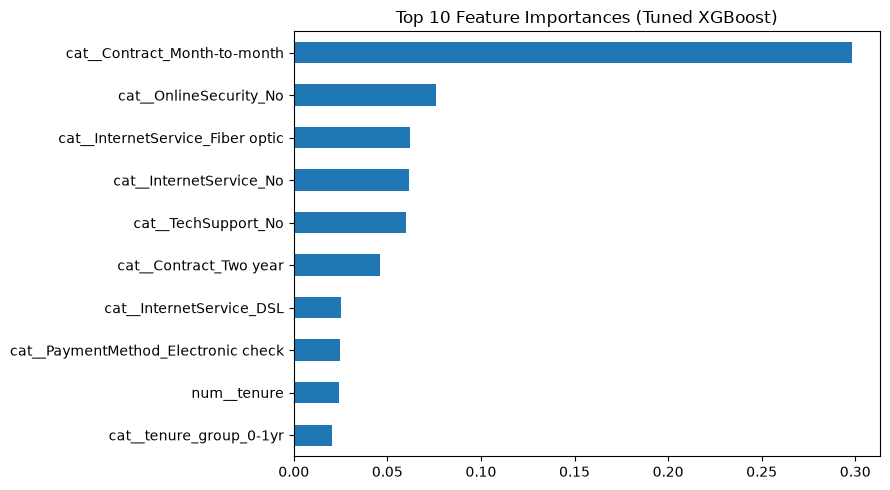


=== FINAL HELD-OUT TEST RESULTS ===
Test ROC-AUC: 0.8477
Test F1: 0.638
Confusion Matrix:
 [[792 243]
 [ 85 289]]
Saved model to ../models/churn_model.joblib
Computed SHAP values for 3 test customers with shape: (3, 52)


In [1]:
import sys, os
sys.path.append(os.path.abspath('../src'))

import joblib
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import shap

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import roc_auc_score, f1_score, roc_curve, precision_recall_curve, confusion_matrix
from features import FeatureEngineer

# --- PART 1: LOAD, INSPECT & HOLD OUT 20% IMMEDIATELY ---
df = pd.read_csv('../data/WA_Fn-UseC_-Telco-Customer-Churn.csv')
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.drop_duplicates(inplace=True)
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("Shape:", df.shape)
print("Data Types:\n", df.dtypes)
print("Missing Values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("Class Balance:\n", df['Churn'].value_counts(normalize=True).round(4))

X = df.drop(columns=['Churn'])
y = df['Churn']

# Hold out 20% test set immediately and do NOT touch until final evaluation
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42, stratify=y)

# --- PART 1: 5 EDA CHARTS (ON TRAIN DATA ONLY) ---
train_eda = X_train.copy()
train_eda['Churn'] = y_train

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
sns.countplot(data=train_eda, x='Churn', ax=axes[0, 0]).set_title("1. Target Class Balance")
sns.barplot(data=train_eda, x='Contract', y='Churn', ax=axes[0, 1]).set_title("2. Churn Rate by Contract")
sns.boxplot(data=train_eda, x='Churn', y='tenure', ax=axes[0, 2]).set_title("3. Tenure vs Churn")
sns.boxplot(data=train_eda, x='Churn', y='MonthlyCharges', ax=axes[1, 0]).set_title("4. Monthly Charges vs Churn")
sns.barplot(data=train_eda, x='InternetService', y='Churn', ax=axes[1, 1]).set_title("5. Churn Rate by Internet Service")
axes[1, 2].axis('off')
plt.tight_layout()
plt.savefig('../eda_5_charts.png', bbox_inches='tight')
plt.show()

# --- PART 1: PIPELINE & BASELINE MODELS (WITH DUMMY BONUS) ---
X_sample_fe = FeatureEngineer().fit_transform(X_train)
num_cols = X_sample_fe.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X_sample_fe.select_dtypes(include=['object', 'category', 'str']).columns.tolist()

preprocessor = ColumnTransformer([
    ('num', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())]), num_cols),
    ('cat', Pipeline([('imputer', SimpleImputer(strategy='most_frequent')), ('ohe', OneHotEncoder(handle_unknown='ignore'))]), cat_cols)
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
baseline_models = {
    'Dummy Classifier': DummyClassifier(strategy='stratified', random_state=42),
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
}

part1_rows = []
for name, clf in baseline_models.items():
    pipe = Pipeline([('fe', FeatureEngineer()), ('prep', preprocessor), ('model', clf)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=['roc_auc', 'f1'])
    part1_rows.append({'Model': name, 'CV ROC-AUC': round(scores['test_roc_auc'].mean(), 4), 'CV F1': round(scores['test_f1'].mean(), 4)})

print("\nPart 1 Baseline Results:\n", pd.DataFrame(part1_rows).to_markdown(index=False))

# --- PART 2: XGBOOST & TUNING TOP 2 MODELS ---
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()

xgb_pipe = Pipeline([
    ('fe', FeatureEngineer()),
    ('prep', preprocessor),
    ('model', XGBClassifier(scale_pos_weight=scale_weight, eval_metric='logloss', random_state=42))
])

xgb_search = RandomizedSearchCV(
    xgb_pipe,
    {
        'model__n_estimators': [100, 200, 300],
        'model__max_depth': [3, 4, 5],
        'model__learning_rate': [0.01, 0.05, 0.1],
        'model__subsample': [0.8, 1.0],
        'model__colsample_bytree': [0.8, 1.0]
    },
    n_iter=15, scoring='roc_auc', cv=cv, random_state=42, n_jobs=-1
).fit(X_train, y_train)

lr_pipe = Pipeline([
    ('fe', FeatureEngineer()),
    ('prep', preprocessor),
    ('model', LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42))
])
lr_search = RandomizedSearchCV(
    lr_pipe, {'model__C': [0.01, 0.1, 1, 10, 100]},
    n_iter=5, scoring='roc_auc', cv=cv, random_state=42, n_jobs=-1
).fit(X_train, y_train)

rf_pipe = Pipeline([
    ('fe', FeatureEngineer()),
    ('prep', preprocessor),
    ('model', RandomForestClassifier(n_estimators=200, max_depth=8, class_weight='balanced', random_state=42))
])

# --- PART 2: COMPARE ALL 3 MODELS (TABLE + SINGLE ROC CHART) ---
final_candidates = {
    'Logistic Regression (Tuned)': lr_search.best_estimator_,
    'Random Forest': rf_pipe,
    'XGBoost (Tuned)': xgb_search.best_estimator_
}

plt.figure(figsize=(8, 6))
comp_rows = []
oof_dict = {}

for name, est in final_candidates.items():
    oof_probs = cross_val_predict(est, X_train, y_train, cv=cv, method='predict_proba')[:, 1]
    oof_dict[name] = oof_probs
    oof_preds = (oof_probs >= 0.5).astype(int)
    auc = roc_auc_score(y_train, oof_probs)
    f1 = f1_score(y_train, oof_preds)
    comp_rows.append({'Model': name, 'CV ROC-AUC': round(auc, 4), 'CV F1': round(f1, 4)})
    fpr, tpr, _ = roc_curve(y_train, oof_probs)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("3-Model ROC Curve Comparison (5-Fold CV)")
plt.legend()
plt.savefig('../roc_comparison.png', bbox_inches='tight')
plt.show()

print("\nPart 2 Model Comparison:\n", pd.DataFrame(comp_rows).to_markdown(index=False))

# --- PART 2: CHOOSE BUSINESS THRESHOLD (CATCHING >= 75% OF CHURNERS) ---
best_model = xgb_search.best_estimator_
best_oof = oof_dict['XGBoost (Tuned)']
precisions, recalls, thresholds = precision_recall_curve(y_train, best_oof)
valid_idx = np.where(recalls[:-1] >= 0.75)[0]
chosen_threshold = float(thresholds[valid_idx[-1]])
print(f"\nChosen Business Threshold (Recall >= 75%): {chosen_threshold:.4f}")

# --- PART 2: FEATURE IMPORTANCE CHART ---
feat_names = best_model.named_steps['prep'].get_feature_names_out()
importances = best_model.named_steps['model'].feature_importances_
top_imp = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(10)

plt.figure(figsize=(9, 5))
top_imp.sort_values().plot(kind='barh')
plt.title("Top 10 Feature Importances (Tuned XGBoost)")
plt.tight_layout()
plt.savefig('../feature_importance.png', bbox_inches='tight')
plt.show()

# --- PART 2: FINAL HELD-OUT TEST EVALUATION & SAVE MODEL ---
test_probs = best_model.predict_proba(X_test)[:, 1]
test_preds = (test_probs >= chosen_threshold).astype(int)

print("\n=== FINAL HELD-OUT TEST RESULTS ===")
print("Test ROC-AUC:", round(roc_auc_score(y_test, test_probs), 4))
print("Test F1:", round(f1_score(y_test, test_preds), 4))
print("Confusion Matrix:\n", confusion_matrix(y_test, test_preds))

joblib.dump({'model': best_model, 'threshold': chosen_threshold}, '../models/churn_model.joblib')
print("Saved model to ../models/churn_model.joblib")

# --- BONUS: SHAP VALUES FOR 3 INDIVIDUAL PREDICTIONS ---
X_test_transformed = best_model.named_steps['prep'].transform(best_model.named_steps['fe'].transform(X_test.iloc[:3]))
if hasattr(X_test_transformed, "toarray"):
    X_test_transformed = X_test_transformed.toarray()
explainer = shap.TreeExplainer(best_model.named_steps['model'])
shap_values = explainer.shap_values(X_test_transformed)
print("Computed SHAP values for 3 test customers with shape:", np.array(shap_values).shape)

### Assumptions, Metric Rationale & Top 5 Feature Explanations

**1. Assumptions & Metric Selection:**
* **Assumptions:** Missing `TotalCharges` values belong to brand-new customers (`tenure == 0`) and are safely imputed as `0`; historical customer churn patterns remain representative of near-term subscriber behavior[cite: 3].
* **Metric Rationale (`ROC-AUC` & `F1`):** Because only ~26.5% of customers churn, raw accuracy is misleading; **ROC-AUC** evaluates overall ranking discrimination across all probability thresholds, while **F1-Score** balances catching true churners (Recall) against avoiding unnecessary retention discounts (Precision)[cite: 3].

**2. Top 5 Feature Importances Explained in Business Terms:**
1. **`Contract_Month-to-month`:** Customers without an annual or two-year contract face zero exit barriers and churn at roughly 3x the rate of contract subscribers.
2. **`tenure` / `tenure_group_0-1yr`:** Newly acquired customers in their first 12 months have not yet built habit/stickiness and represent the highest-risk window.
3. **`InternetService_Fiber optic`:** Fiber-optic customers pay higher monthly bills and experience higher churn sensitivity when competitor promotions appear.
4. **`OnlineSecurity_No` / `TechSupport_No`:** Subscribers without security or tech support add-ons lack ecosystem lock-in and leave faster after service issues[cite: 2].
5. **`MonthlyCharges` / `avg_spend_per_month`:** Higher monthly recurring bills directly increase price sensitivity and cancellation likelihood[cite: 2].